# Example of the `aitlas` toolbox in the context of multi label image classification

This notebook shows a sample implementation of a multi label image classification using the `aitlas` toolbox using the MLRS Net multi label dataset.

In [ ]:
from aitlas.datasets import MLRSNetMultiLabelDataset
from aitlas.models import ResNet50MultiLabel
from aitlas.transforms import ResizeCenterCropFlipHVToTensor, ResizeCenterCropToTensor
from aitlas.utils import image_loader

## Load the dataset

In [4]:
dataset_config = {
    "data_dir": "/home/dragik/data/MLRSNet/images", 
    "csv_file": "/home/dragik/data/MLRSNet/multilabels.txt"
    }
dataset = MLRSNetMultiLabelDataset(dataset_config)

## Show images from the dataset

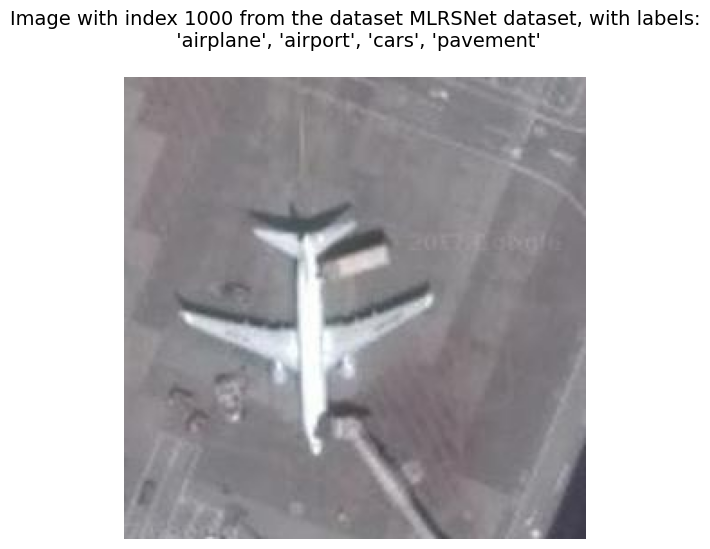

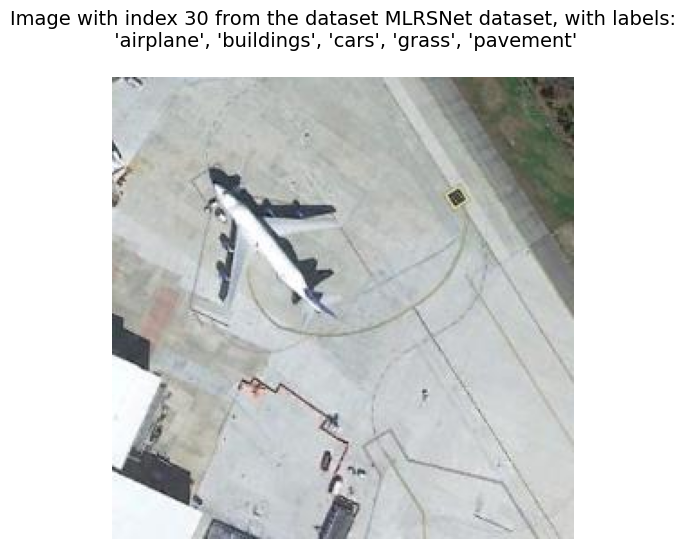

In [5]:
fig1 = dataset.show_image(1000)
fig2 = dataset.show_image(30)

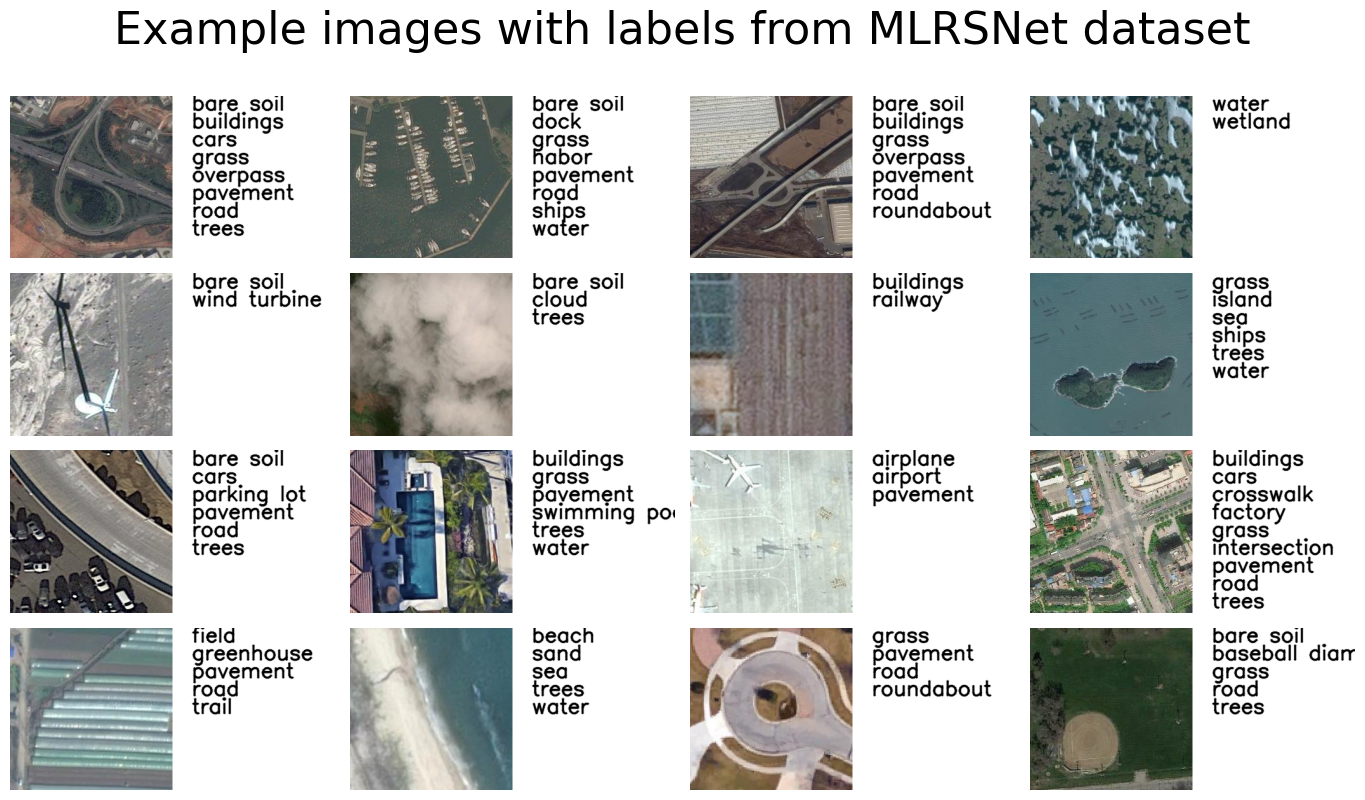

In [7]:
fig3 = dataset.show_batch(16)

## Inspect the data

In [8]:
dataset.show_samples()

,image,airplane,airport,bare soil,baseball diamond,basketball court,beach,bridge,buildings,cars,...,tennis court,terrace,track,trail,transmission tower,trees,water,chaparral,wetland,wind turbine
0,desert_00001,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
1,desert_00002,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
2,desert_00003,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,desert_00004,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
4,desert_00005,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
5,desert_00006,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
6,desert_00007,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
7,desert_00008,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
8,desert_00009,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
9,desert_00010,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [9]:
dataset.data_distribution_table()

,Label,Count
1,airplane,2306
2,airport,2480
3,bare soil,39345
4,baseball diamond,1996
5,basketball court,3726
6,beach,2485
7,bridge,2772
8,buildings,51305
9,cars,34013
10,cloud,1798


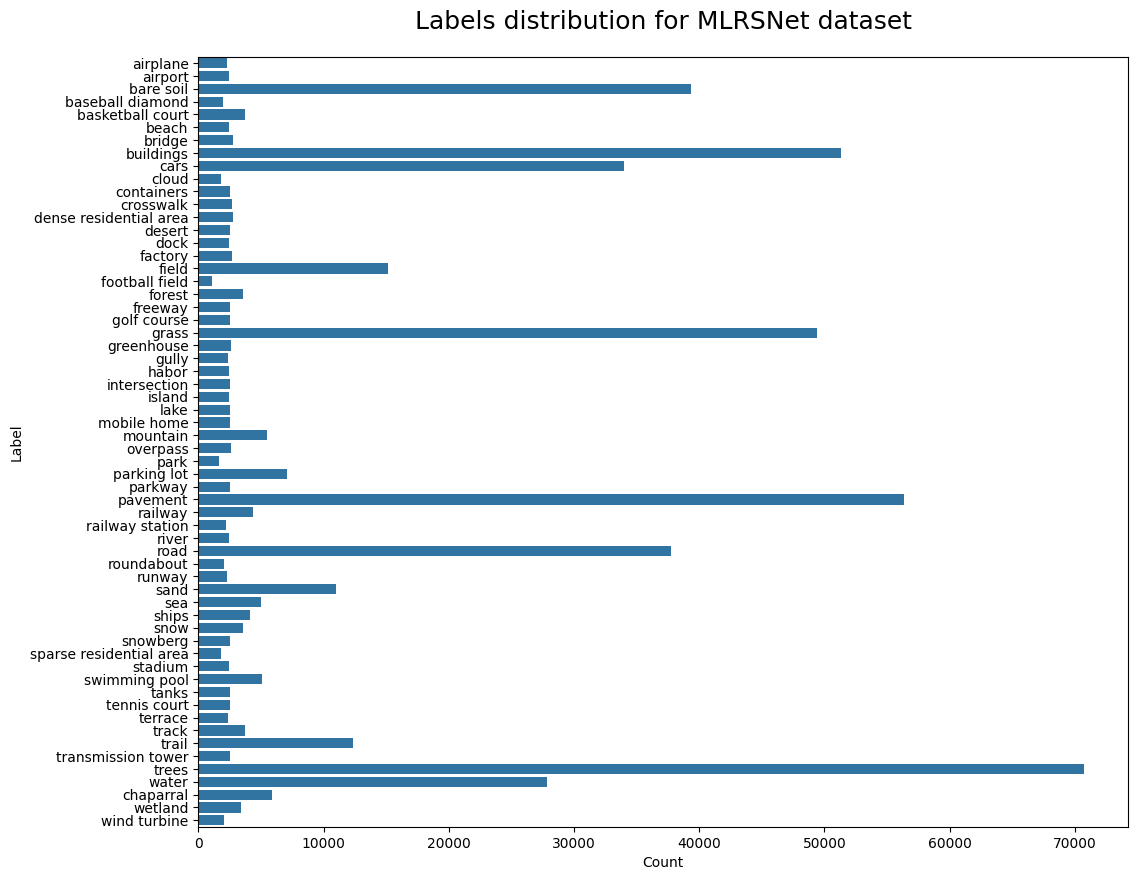

In [10]:
fig = dataset.data_distribution_barchart()

## Load train and test splits

In [14]:
train_dataset_config = {
    "batch_size": 16,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/MLRSNet/images",
    "csv_file": "/home/dragik/data/MLRSNet/train.csv",
}

train_dataset = MLRSNetMultiLabelDataset(train_dataset_config)
train_dataset.transform = ResizeCenterCropFlipHVToTensor()

test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/MLRSNet/images",
    "csv_file": "/home/dragik/data/MLRSNet/val.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"],
}

test_dataset = MLRSNetMultiLabelDataset(test_dataset_config)
len(train_dataset), len(test_dataset)

(65261, 21604)

## Setup and create the model for training

In [15]:
epochs = 10
model_directory = "/home/dragik/data/experiments/MLRSNet"
model_config = {
    "num_classes": 60,
    "learning_rate": 0.0001,
    "pretrained": True,
    "threshold": 0.5,
    "metrics": ["accuracy", "precision", "recall", "f1_score"],
}
model = ResNet50MultiLabel(model_config)
model.prepare()

## Training and evaluation

In [16]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=test_dataset,
    run_id="1",
)

2026-08-24 08:12:48,620 INFO Starting training.
training: 100%|██████████| 4079/4079 [03:06<00:00, 21.86it/s]
2026-08-24 08:15:55,352 INFO epoch: 1, time: 187, loss:  0.08940
testing on train set: 100%|██████████| 4079/4079 [01:26<00:00, 47.06it/s]
2026-08-24 08:17:22,813 INFO Accuracy:0.979558235393267, Accuracy per Class:[0.99269089 0.98950369 0.83146136 0.99941772 0.99155698 0.99711926
 0.99486677 0.91259711 0.91693354 0.99802332 0.99967822 0.99290541
 0.99788541 0.99803864 0.99941772 0.99106664 0.954138   0.9905763
 0.98999402 0.99730314 0.99785477 0.8488071  0.99882012 0.99187876
 0.99941772 0.99695071 0.999004   0.99782412 0.9988048  0.99203199
 0.99371753 0.99567889 0.96431253 0.99354898 0.94293682 0.98801735
 0.98849236 0.99647569 0.90677434 0.99543372 0.99632246 0.98939642
 0.9968128  0.98473821 0.99403932 0.99806929 0.99843705 0.99574018
 0.98875285 0.99954031 0.99768621 0.9951579  0.99068356 0.94145048
 0.99774751 0.88686965 0.92952912 0.98651568 0.9846003  0.99944837], Prec

0.03141253442943851

## Predictions

2026-08-24 09:30:43,988 INFO Loading checkpoint /home/dragik/data/experiments/MLRSNet/checkpoint.pth.tar
2026-08-24 09:30:46,383 INFO Loaded checkpoint /home/dragik/data/experiments/MLRSNet/checkpoint.pth.tar at epoch 11


22296


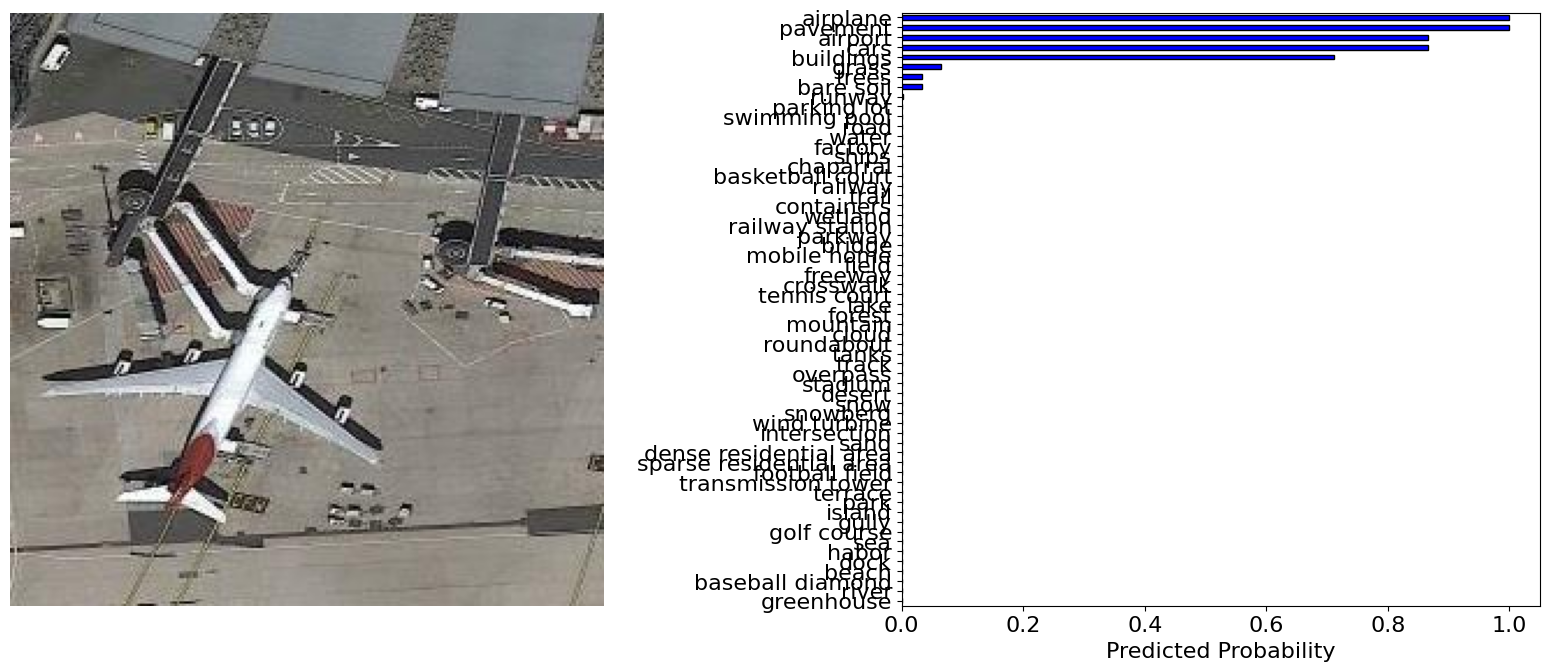

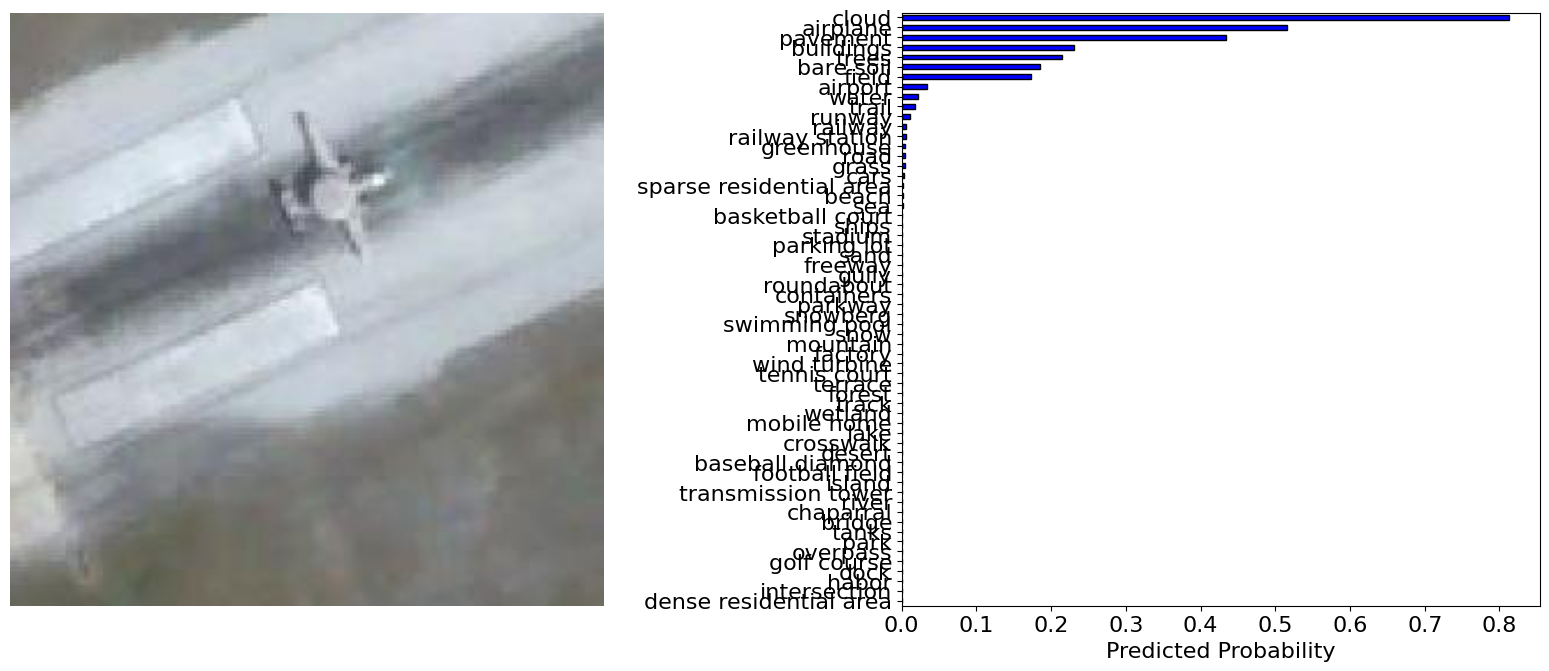

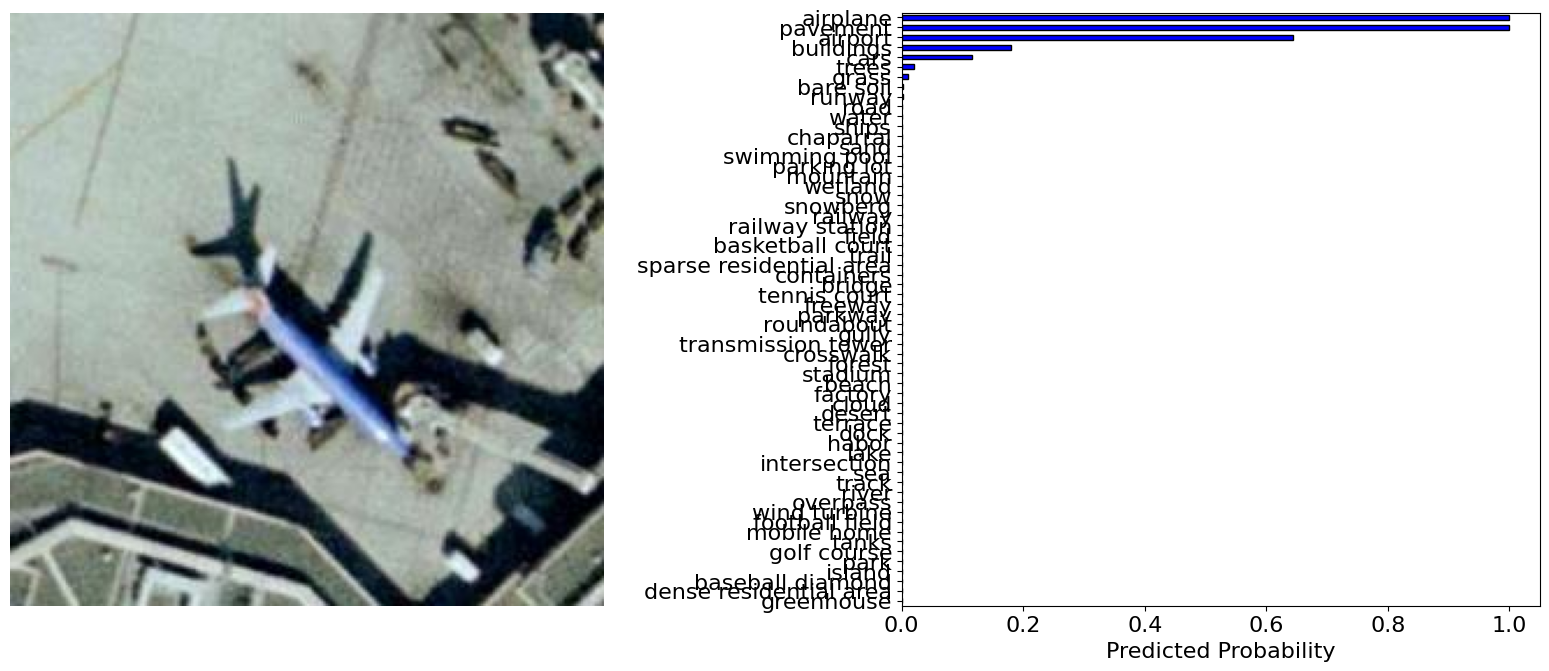

In [20]:
model_path = "/home/dragik/data/experiments/MLRSNet/checkpoint.pth.tar"
labels = [
    "airplane",
    "airport",
    "bare soil",
    "baseball diamond",
    "basketball court",
    "beach",
    "bridge",
    "buildings",
    "cars",
    "cloud",
    "containers",
    "crosswalk",
    "dense residential area",
    "desert",
    "dock",
    "factory",
    "field",
    "football field",
    "forest",
    "freeway",
    "golf course",
    "grass",
    "greenhouse",
    "gully",
    "habor",
    "intersection",
    "island",
    "lake",
    "mobile home",
    "mountain",
    "overpass",
    "park",
    "parking lot",
    "parkway",
    "pavement",
    "railway",
    "railway station",
    "river",
    "road",
    "roundabout",
    "runway",
    "sand",
    "sea",
    "ships",
    "snow",
    "snowberg",
    "sparse residential area",
    "stadium",
    "swimming pool",
    "tanks",
    "tennis court",
    "terrace",
    "track",
    "trail",
    "transmission tower",
    "trees",
    "water",
    "chaparral",
    "wetland",
    "wind turbine",
]
transform = ResizeCenterCropToTensor()
model.load_model(model_path)

test_dataset_config = {
    "data_dir": "/home/dragik/data/MLRSNet/images",
    "csv_file": "/home/dragik/data/MLRSNet/test.csv"
}

test_dataset = MLRSNetMultiLabelDataset(test_dataset_config)
print(len(test_dataset))

image = test_dataset[0][0]
fig = model.predict_image(image, labels, transform)

image = test_dataset[10][0]
fig = model.predict_image(image, labels, transform)

image = test_dataset[100][0]
fig = model.predict_image(image, labels, transform)